# `test_long_results.ipynb`

Connor Shrader / 09-24-2025

The purpose of this file is to run long metric computations on individual clones, with the goal of debugging. This file should not be used to compute all results, since this takes very long. Instead, use `long_metrics.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from saving_loading import find_scenarios, load_all_scenarios
from long_metrics import process_clone

import testis_model as tm

In [2]:
fish_data, clone_data = load_all_scenarios(['real', 'n500_r36_y3'])

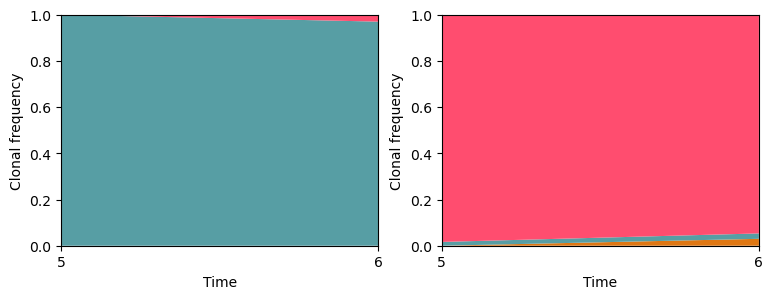

In [3]:
fish_d = fish_data['real', 6]
data = clone_data['real', 6, 2]

fig, ax = plt.subplots(1, 2, figsize = (9, 3))
tm.visualize.plot(data, ax = ax[0])
tm.visualize.plot(fish_d, ax = ax[1])

In [4]:
fish_d

,group,fish,time,replicate,obs_result,n_sperm
0,real,23,4.86,1,"(320, 0, 3, 3, 0)",371
1,real,23,4.86,2,"(282, 2, 0, 0, 0)",371
2,real,23,5.76,1,"(265, 0, 3, 6, 3)",371
3,real,23,5.76,2,"(297, 0, 4, 0, 2)",371
4,real,23,5.76,3,"(287, 0, 2, 2, 2)",371


In [10]:
import importlib
importlib.reload(tm.likelihood)
lm = tm.likelihood.LikelihoodModel(1000)

In [5]:
series = process_clone(data)

In [6]:
series

{'init_time': 5.76,
 'init_freq': 0.02987012987012987,
 'r_opt': np.float64(6.26534808487219),
 'if_opt': np.float64(0.006895907668486743),
 'l_max': np.float64(-13.570775873987925),
 'lower': 2.5667549795254647,
 'upper': 15.873673422162236,
 'if_null': np.float64(0.010488194562473291),
 'l_null': np.float64(-22.51259689325514)}

In [11]:
lm.max_likelihood2(data, init_time = 4, statistic = 4)

(np.float64(9.850676935033128),
 np.float64(-17.39014920236133),
 2.1082271070020027,
 67.0689154870699)

In [9]:
lm.fit_moran_rate_variance(data)

(nan, np.float64(0.00808564118076893))

In [35]:
l, alpha, log_scale = lm.likelihood(data, 0, 0.05956308909820755, return_alpha = True, f_cutoff = 1e-20, init_time=4)
print(l)

-76.70249068426963


In [34]:
l, alpha, log_scale = lm.likelihood(data, 1.1584231001755307, 0.05956308909820755, return_alpha = True, f_cutoff = 1e-20, init_time=4)
print(l)

-78.7019734793464


In [274]:
len(alpha)

11

In [275]:
np.sum(alpha, axis = 1)

array([25.10056837, 34.77022965,  1.02335391,  4.94611867,  3.14061856,
        1.0292066 ,  1.00013228,  1.00000078,  1.00000001,  4.109853  ,
        7.63695275])

In [276]:
lm.max_likelihood(agg)

(np.float64(378.2487954092233),
 np.float64(0.7518939393939394),
 -1000000.0,
 nan,
 None)

In [277]:
ifn, ln = lm.max_likelihood_null(agg)
print(ifn)

0.12681107087177773


In [278]:
lm.max_likelihood(agg, ic = [5, 0.75])

(np.float64(4.93295719835215),
 np.float64(0.6842961876830812),
 np.float64(-83.14907053260464),
 0.006043446778362328,
 9.442352701786985)

In [211]:
lm.likelihood(data, 1.542e-12, 0.76538)

np.float64(-261.46672018426455)

In [177]:
log_scaling

array([-3.78899521e+00, -1.27312762e+00, -8.18325728e-01,  1.20330908e+00,
        0.00000000e+00,  0.00000000e+00,  2.21512570e-03,  0.00000000e+00,
        4.32796634e-05,  0.00000000e+00,  0.00000000e+00,  5.02418498e-07,
        0.00000000e+00,  0.00000000e+00,  4.98026952e-09,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,            -inf,
                  -inf,            -inf,            -inf,            -inf,
                  -inf,            -inf,            -inf,            -inf,
                  -inf,            -inf,            -inf,            -inf,
                  -inf,            -inf,            -inf,            -inf,
                  -inf])

In [179]:
np.sum(alpha, axis = 1)

array([5.37546971, 4.48905006, 3.73233234, 1.011512  , 1.00498327,
       1.00273514, 1.00011549, 1.00005436, 1.00000232, 1.00000108,
       1.00000061, 1.00000002, 1.00000001, 1.00000001, 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        ])

/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_3253/2723117177.py:1: RuntimeWarning: divide by zero encountered in log
  plt.plot(np.log(alpha[2, :]))


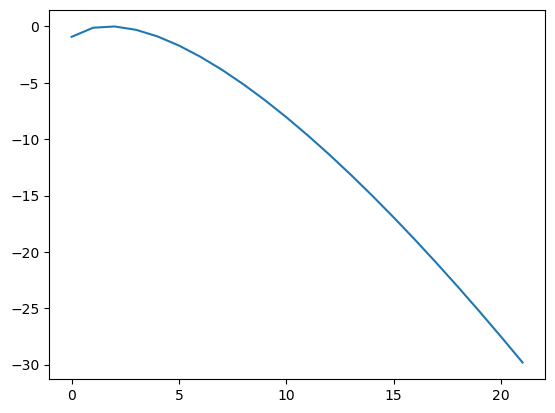

In [189]:
plt.plot(np.log(alpha[2, :]))

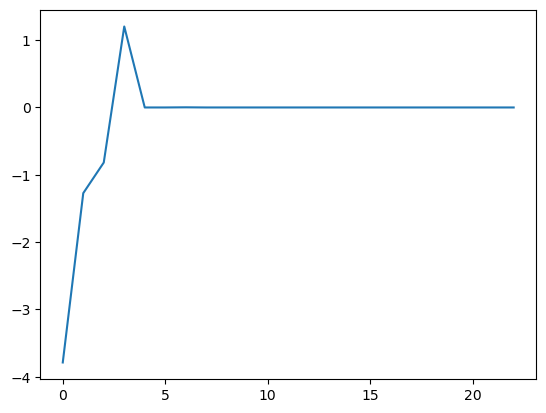

In [178]:
plt.plot(log_scaling)

In [161]:
lm.max_likelihood(data, ic = [1, 0.01], init_time = 4)

(np.float64(0.0),
 np.float64(0.0010000628553151654),
 np.float64(-29.02042496641188),
 0.0,
 0.31420665767473704)

In [11]:
lm.max_likelihood_null(data)

(np.float64(0.13139421358504721), np.float64(-177.88092984075124))

In [94]:
from scipy.stats import binom
from testis_model.likelihood import forward_algorithm

In [101]:
def dT_dr(self, r):
    if r == 0:
        # derivative of expm(0*R) = I is just R
        return self.R
    else:
        scaled_vecs = self.evecs * (self.evals * np.exp(r * self.evals))
        return scaled_vecs @ self.evecs_inv

In [116]:
def likelihood_and_grad(self, samples, r, init_freq, f_cutoff=1e-10):
    # Forward pass
    times = samples['time']
    n_sperms = samples['n_sperm']
    t_gaps = [times[0] if i == 0 else times[i] - times[i-1] for i in range(len(times))]
    Ts = [self.get_T(t_gap * r) for t_gap in t_gaps]
    Es = [self.get_E(n_sperms[i]) for i in range(len(times))]
    obs = np.array(samples['obs_result'].apply(lambda x: x[0]))

    init_state = binom.pmf(np.arange(self.n_stem+1), n=self.n_stem, p=init_freq)
    alpha, log_scaling = forward_algorithm(init_state, obs, Ts, Es, f_cutoff)

    # Backward pass (implement a scaled backward_algorithm)
    beta = backward_algorithm(obs, Ts, Es, f_cutoff, log_scaling)

    # Posterior expectations
    gammas = [alpha[t] * beta[t] for t in range(len(obs))]
    gammas = [g / g.sum() for g in gammas]
    # print([g.sum() for g in gammas])

    xis = []
    for t in range(1, len(obs)):
        xi = alpha[t-1][:,None] * Ts[t] * Es[t][:,obs[t]] * beta[t]
        xi /= xi.sum()
        xis.append(xi)

    # Log-likelihood
    l = np.sum(alpha[-1,:])
    log_l = np.sum(log_scaling) + np.log(l)

    # Gradient wrt init_freq
    grad_init = sum(
        gammas[0][i] * (i/init_freq - (self.n_stem - i)/(1-init_freq))
        for i in range(self.n_stem+1)
    )

    # Gradient wrt r
    grad_r = 0.0
    for t, xi in enumerate(xis, start=1):
        dT = dT_dr(self, t_gaps[t]*r) * t_gaps[t]  # chain rule
        mask = Ts[t] > 0
        grad_r += np.sum(xi[mask] * (dT[mask] / Ts[t][mask]))

    return log_l, np.array([grad_r, grad_init])

In [117]:
import numpy as np
from numba import njit

@njit
def backward_algorithm(obs, Ts, Es, f_cutoff, log_scaling):
    n_obs = len(obs)
    n_states = Ts[0].shape[0]
    beta = np.zeros((n_obs, n_states))

    # Initialization: beta at last time step
    beta[-1, :] = 1.0
    # Apply scaling
    beta[-1, :] /= np.max(beta[-1, :])

    # Recursion backwards
    for t in range(n_obs - 2, -1, -1):
        T = Ts[t+1]
        E = Es[t+1]
        max_f = np.max(beta[t+1, :])
        threshold = max_f * f_cutoff
        active_cols = np.where(beta[t+1, :] >= threshold)[0]

        for i in range(n_states):
            total = 0.0
            for j in active_cols:
                total += T[i, j] * E[j, obs[t+1]] * beta[t+1, j]
            beta[t, i] = total

        # Apply scaling consistent with forward
        max_val = np.max(beta[t, :])
        if max_val > 0:
            beta[t, :] /= max_val
            # subtract log scaling so alpha*beta stays consistent
            beta[t, :] *= np.exp(log_scaling[t+1])

    return beta

In [138]:
likelihood_and_grad(lm, data, 1, 0.08601)

(np.float64(-188.9994440080834), array([ -2.29580066, 348.08400512]))

In [142]:
import numpy as np
from scipy.optimize import minimize

# Wrapper for SciPy: we want to maximize log-likelihood, so minimize the negative
def objective(params, lm, data):
    r, init_freq = params
    true_init = 1 / (1 + np.exp(-init_freq))
    logL, grad = likelihood_and_grad(lm, data, r, true_init)
    return -logL, -grad  # negate both value and gradient

# Initial guess
x0 = np.array([1.0, 0])

# Bounds (if needed, e.g. init_freq in (0,1))
bounds = [(0, 1000), (1e-6, 1-1e-6)]

# Run optimization
result = minimize(
    fun=objective,
    x0=x0,
    args=(lm, data),
    method='trust-constr',
    jac=True,                # tells SciPy we’re providing the gradient
    bounds=bounds,
    options={'disp': True}
)

print("Success:", result.success)
print("Message:", result.message)
print("Optimal parameters:", result.x)
print("Maximized log-likelihood:", -result.fun)

/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_6015/1815908631.py:18: RuntimeWarning: invalid value encountered in divide
  gammas = [g / g.sum() for g in gammas]
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:317: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x107e14150>>
Traceback (most recent call last):
  File "/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 

KeyboardInterrupt



In [127]:
lm.max_likelihood(data)

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


True
CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
21


(np.float64(0.2119024693001844),
 np.float64(0.0860129170450802),
 np.float64(-187.400806386355),
 0.0,
 2.1258654904127003)

In [129]:
lm.max_likelihood_null(data)

(np.float64(0.13139420513315134), np.float64(-177.8809298407513))

# Debug

In [11]:
import testis_modeling2 as tm
import importlib
import warnings
importlib.reload(tm)

<module 'testis_modeling2' from '/Users/connor/Documents/github/gagnon/testis_modeling2/__init__.py'>

In [12]:
lm = tm.likelihood.LikelihoodModel(1000)

In [36]:
lm.likelihood(data, 0, 0.29080563042827196)

np.float64(-64.3915624588825)

In [37]:
lm.max_likelihood_null2(data)

(np.float64(0.2908328943163452), np.float64(-64.39156089088853))